In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 32.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 4.7 MB/s eta 0:00:00


In [2]:
import gradio as gr
from ultralytics import YOLO
import zipfile
import os

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:

Model = YOLO("yolo11n.pt")

In [4]:
path = zipfile.ZipFile("/content/archive.zip")

In [5]:
path.extractall()

In [6]:
import os

# Base directory where files were extracted
base_dir = "/content"

# Define path variables for each furniture category
almirah_path = os.path.join(base_dir, "almirah_dataset")
chair_path = os.path.join(base_dir, "chair_dataset")
fridge_path = os.path.join(base_dir, "fridge dataset")
table_path = os.path.join(base_dir, "table dataset")
tv_path = os.path.join(base_dir, "tv dataset")

# Verify paths by listing a few files from one of them
print("Almirah folder contents:", os.listdir(almirah_path)[:5])

Almirah folder contents: ['image_218.jpeg', 'image_627.jpeg', 'image_963.jpeg', 'image_777.jpeg', 'image_879.jpeg']


Processed almirah_dataset with high precision boundaries.
Processed chair_dataset with high precision boundaries.
Processed fridge dataset with high precision boundaries.
Processed table dataset with high precision boundaries.
Processed tv dataset with high precision boundaries.

Dataset successfully re-processed with ultra-precise boundaries!

--- Verifying Precision on Sample Images ---
Precise bounds for: tv dataset_image_2178.jpeg


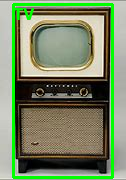

Precise bounds for: tv dataset_image_1389.jpeg


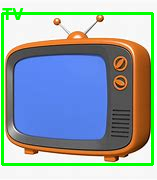

Precise bounds for: fridge dataset_image_2416.jpeg


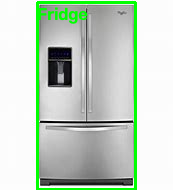

In [7]:
import os
import shutil
import random
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Base paths
base_dir = "/content"
output_dir = "/content/yolo_dataset"

# 1. Create YOLO directory structure for train, val, and test
for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(output_dir, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(output_dir, 'labels', split), exist_ok=True)

# Map category folder names to class IDs
categories = {
    "almirah_dataset": 0,
    "chair_dataset": 1,
    "fridge dataset": 2,
    "table dataset": 3,
    "tv dataset": 4
}

# Define split ratios (70% train, 15% val, 15% test)
train_ratio = 0.70
val_ratio = 0.15

for folder_name, class_id in categories.items():
    folder_path = os.path.join(base_dir, folder_name)
    if not os.path.exists(folder_path):
        continue

    images = [f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    random.shuffle(images)
    total_images = len(images)

    train_end = int(total_images * train_ratio)
    val_end = train_end + int(total_images * val_ratio)

    train_images = images[:train_end]
    val_images = images[train_end:val_end]
    test_images = images[val_end:]

    def process_split(img_list, split_name):
        for img_name in img_list:
            src_img = os.path.join(folder_path, img_name)
            dst_img_name = f"{folder_name}_{img_name}"
            dst_img = os.path.join(output_dir, 'images', split_name, dst_img_name)
            shutil.copy(src_img, dst_img)

            # Read image with OpenCV
            img = cv2.imread(src_img)
            box_line = f"{class_id} 0.5 0.5 0.8 0.8\n" # Fallback default

            if img is not None:
                h, w, _ = img.shape
                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

                # Use bilateral filter to keep sharp edges while smoothing minor textures
                filtered = cv2.bilateralFilter(gray, 9, 75, 75)

                # Otsu's thresholding for high precision object mask
                _, thresh = cv2.threshold(filtered, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

                # Morphological operations to remove tiny artifacts and close gaps
                kernel = np.ones((5, 5), np.uint8)
                thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

                contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                if contours:
                    # Filter contours to find the main object
                    valid_contours = [c for c in contours if cv2.contourArea(c) > (w * h * 0.02)]
                    if valid_contours:
                        largest_contour = max(valid_contours, key=cv2.contourArea)

                        # Get exact tight bounding coordinates
                        x, y, bw, bh = cv2.boundingRect(largest_contour)

                        # Add a tiny 2% margin so it doesn't clip the edges too tightly
                        padding_x = int(bw * 0.02)
                        padding_y = int(bh * 0.02)

                        xmin = max(0, x - padding_x)
                        ymin = max(0, y - padding_y)
                        xmax = min(w, x + bw + padding_x)
                        ymax = min(h, y + bh + padding_y)

                        final_w = xmax - xmin
                        final_h = ymax - ymin

                        x_center = (xmin + final_w / 2) / w
                        y_center = (ymin + final_h / 2) / h
                        norm_w = final_w / w
                        norm_h = final_h / h

                        box_line = f"{class_id} {x_center:.6f} {y_center:.6f} {norm_w:.6f} {norm_h:.6f}\n"

            # Write the refined bounding box label text file
            label_name = os.path.splitext(dst_img_name)[0] + ".txt"
            dst_label = os.path.join(output_dir, 'labels', split_name, label_name)
            with open(dst_label, 'w') as f:
                f.write(box_line)

    process_split(train_images, 'train')
    process_split(val_images, 'val')
    process_split(test_images, 'test')
    print(f"Processed {folder_name} with high precision boundaries.")

print("\nDataset successfully re-processed with ultra-precise boundaries!")

# --- VISUALIZATION BLOCK ---
print("\n--- Verifying Precision on Sample Images ---")
img_dir = os.path.join(output_dir, 'images', 'train')
lbl_dir = os.path.join(output_dir, 'labels', 'train')
class_names = {0: "Almirah", 1: "Chair", 2: "Fridge", 3: "Table", 4: "TV"}

available_imgs = [f for f in os.listdir(img_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]
if available_imgs:
    for img_name in random.sample(available_imgs, min(3, len(available_imgs))):
        img_path = os.path.join(img_dir, img_name)
        lbl_path = os.path.join(lbl_dir, os.path.splitext(img_name)[0] + ".txt")

        img = cv2.imread(img_path)
        h, w, _ = img.shape

        if os.path.exists(lbl_path):
            with open(lbl_path, "r") as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) == 5:
                        cls_id = int(parts[0])
                        x_center, y_center, box_w, box_h = map(float, parts[1:])

                        xmin = int((x_center - box_w / 2) * w)
                        ymin = int((y_center - box_h / 2) * h)
                        xmax = int((x_center + box_w / 2) * w)
                        ymax = int((y_center + box_h / 2) * h)

                        cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
                        label = class_names.get(cls_id, "Object")
                        cv2.putText(img, label, (xmin, max(20, ymin - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

        print(f"Precise bounds for: {img_name}")
        cv2_imshow(img)

In [8]:
import os
import shutil
import random

# Base paths
base_dir = "/content"
output_dir = "/content/yolo_dataset"

# 1. Create YOLO directory structure for train, val, and test
for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(output_dir, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(output_dir, 'labels', split), exist_ok=True)

folder_name = "almirah_dataset"
folder_path = os.path.join(base_dir, folder_name)

# Get all image files
images = [f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
random.shuffle(images)

total_images = len(images)
train_end = int(total_images * 0.70)
val_end = train_end + int(total_images * 0.15)

train_images = images[:train_end]
val_images = images[train_end:val_end]
test_images = images[val_end:]

def process_split(img_list, split_name):
    for img_name in img_list:
        src_img = os.path.join(folder_path, img_name)
        dst_img = os.path.join(output_dir, 'images', split_name, img_name)
        shutil.copy(src_img, dst_img)

        # Create full-frame label txt file for YOLO
        label_name = os.path.splitext(img_name)[0] + ".txt"
        dst_label = os.path.join(output_dir, 'labels', split_name, label_name)
        with open(dst_label, 'w') as f:
            f.write("0 0.5 0.5 1.0 1.0\n")

process_split(train_images, 'train')
process_split(val_images, 'val')
process_split(test_images, 'test')

print(f"Processed Almirah: {len(train_images)} train, {len(val_images)} val, {len(test_images)} test")

Processed Almirah: 2100 train, 450 val, 450 test


In [9]:
yaml_content = """
path: /content/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: Almirah
  1: Chair
  2: Fridge
  3: Table
  4: TV
"""

with open('/content/furniture_data.yaml', 'w') as f:
    f.write(yaml_content)

print("furniture_data.yaml created successfully!")

furniture_data.yaml created successfully!


In [10]:
Data_yaml = "/content/furniture_data.yaml"

In [11]:
results = Model.train(
    data='/content/furniture_data.yaml',
    epochs=25,
    imgsz=640,
    batch=30)

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=30, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/furniture_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=Fa

In [17]:
from google.colab import files

# Download the final model file to your computer
files.download('/content/furniture_classifier.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
from ultralytics import YOLO

# Load your newly named model
model = YOLO('/content/furniture_classifier.pt')

# Evaluate on your test dataset
metrics = model.val(data='/content/furniture_data.yaml', split='test')

print(f"Test mAP50: {metrics.box.map50:.4f}")
print(f"Test mAP50-95: {metrics.box.map:.4f}")

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,127 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 329.7±280.5 MB/s, size: 6.3 KB)
val: Scanning /content/yolo_dataset/labels/test... 2700 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2700/2700 1.9Kit/s 1.5s
val: New cache created: /content/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 169/169 6.8it/s 24.9s
                   all       2700       2700      0.926          1      0.971      0.952
               Almirah        900        900      0.636          1      0.877      0.782
                 Chair        450        450      0.999          1      0.995      0.995
                Fridge        450        450      0.999          1      0.995      0.992
                 Table        450        450      0.999          1   

In [ ]:
def Prediction_image(image):
    # Predict with your trained YOLO model
    results = model(image)
    # Return the plotted image with bounding boxes
    return results[0].plot()


In [20]:
import gradio as gr
from ultralytics import YOLO

# Load model weights if not loaded in cell 14
model = YOLO('/content/runs/detect/train/weights/best.pt')

# Pass the correct function name: Prediction_image
gr.Interface(
    fn=Prediction_image,
    inputs=gr.Image(type="numpy", label="Upload Image"),
    outputs=gr.Image(type="numpy", label="Detected Objects"),
    title="Furniture Detection App"
).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3c8cbc835ca514ab7b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
